# Univariate Analysis — Summarising One Variable

Having *looked* at the whole table, we now zoom in on **one column at a time**
(*univariate* = one variable). In Notebook 1 we noticed body mass varies enormously —
here we get the tools to see *why* that's a clue.

### What you will learn

| Section | Topic |
|---------|-------|
| 1 | The centre of a numeric column (mean, median, mode) |
| 2 | The spread of a numeric column (range, std, IQR) |
| 3 | Histograms and distribution shape (skew, **bimodality**) |
| 4 | Box plots and spotting outliers |
| 5 | Summarising a categorical column (counts, bar charts) |

**Dataset:** Palmer Penguins (via seaborn).
        

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 110

print("Setup complete.")

Setup complete.


In [2]:
# The Palmer Penguins dataset ships with seaborn — no download needed.
df = sns.load_dataset("penguins")
print(f"Shape: {df.shape}")
df.head()

Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


---
## Section 1 — The Centre of a Numeric Column

Three "typical value" measures, shown for `body_mass_g`:
- **Mean** — the average. Sensitive to extreme values.
- **Median** — the middle value when sorted. Robust to extremes.
- **Mode** — the most frequent value.
        

In [3]:
print("Mean body mass  :", round(df["body_mass_g"].mean(), 1), "g")
print("Median body mass:", df["body_mass_g"].median(), "g")
print("Mode body mass  :", df["body_mass_g"].mode().tolist(), "g")
        

Mean body mass  : 4201.8 g
Median body mass: 4050.0 g
Mode body mass  : [3800.0] g


When the **mean ≈ median**, the distribution is roughly symmetric; a large gap signals **skew**.

---
## Section 2 — The Spread

- **Range** = max − min
- **Standard deviation** (`std`) ≈ the average distance from the mean
- **IQR** (Interquartile Range) = 75th − 25th percentile — the middle half of the data;
  robust to outliers.
        

In [4]:
col = df["body_mass_g"].dropna()
print("Min  :", col.min())
print("Max  :", col.max())
print("Range:", col.max() - col.min())
print("Std  :", round(col.std(), 1))

q1, q3 = col.quantile(0.25), col.quantile(0.75)
print("Q1:", q1, " Q3:", q3, " IQR:", q3 - q1)
        

Min  : 2700.0
Max  : 6300.0
Range: 3600.0
Std  : 802.0
Q1: 3550.0  Q3: 4750.0  IQR: 1200.0


---
## Section 3 — Histograms and Shape

A **histogram** chops a numeric column into bins and counts how many values fall in each.
It is the best way to *see* a distribution. Let's plot flipper length:
        

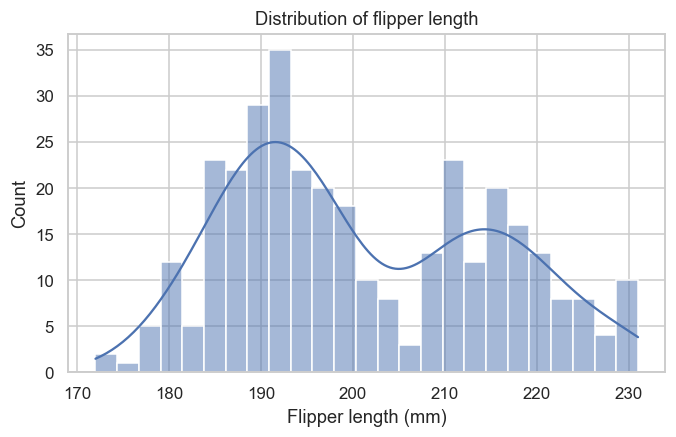

In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(df["flipper_length_mm"], bins=25, kde=True)   # kde adds a smooth curve
plt.title("Distribution of flipper length")
plt.xlabel("Flipper length (mm)"); plt.ylabel("Count")
plt.show()
        

> That histogram is **bimodal**: it has two clear peaks instead of a single bell. A
> bimodal shape is one of the strongest signals in EDA — it almost always means the data
> is **two (or more) different groups stacked on top of each other**. This is the visual
> smoking gun for the "huge spread" mystery from Notebook 1. In Notebook 3 we'll prove
> the humps are *species*.

**Reading shape in general:**
- **Right-skewed** (long right tail): mean > median.
- **Left-skewed** (long left tail): mean < median.
- **Symmetric**: mean ≈ median.
        

---
## Section 4 — Box Plots and Outliers

A **box plot** shows the median, the IQR box, whiskers, and **dots for potential
outliers**.
        

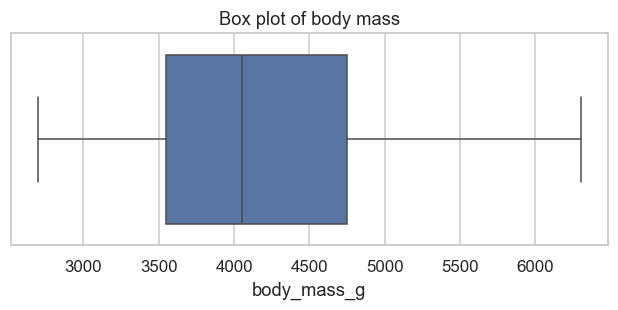

In [7]:
plt.figure(figsize=(7, 2.5))
sns.boxplot(x=df["body_mass_g"])
plt.title("Box plot of body mass")
plt.show()
        

A common rule of thumb: a value is a potential outlier if it lies more than **1.5 × IQR** beyond Q1 or Q3.

In [8]:
def find_outliers(series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s < low) | (s > high)]

print("Number of body-mass outliers:", len(find_outliers(df["body_mass_g"])))
        

Number of body-mass outliers: 0


> Here there are **no** body-mass outliers — the spread is real structure (groups), not a few stray points. That distinction matters.

---
## Section 5 — Summarising a Categorical Column

Mean and std make no sense for text, so we **count categories** with `value_counts()`.
        

In [9]:
df["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [10]:
df["island"].value_counts(normalize=True).round(3)   # as proportions

island
Biscoe       0.488
Dream        0.360
Torgersen    0.151
Name: proportion, dtype: float64

And we picture categories with a **bar chart** (one bar per category):

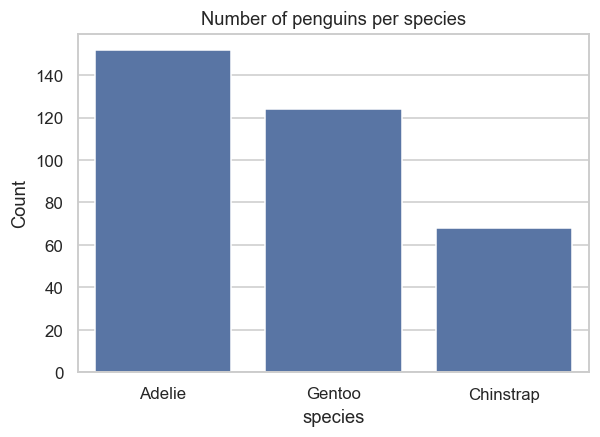

In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="species", order=df["species"].value_counts().index)
plt.title("Number of penguins per species")
plt.xlabel("species"); plt.ylabel("Count")
plt.show()
        

> ⚠️ **Histogram vs. bar chart:** a *histogram* is for **numeric** data (bins of a
> continuous range, bars touch). A *bar chart* is for **categorical** data (one bar per
> category, with gaps). Using the wrong one is a classic beginner mistake.
        

---
## Key Takeaways

1. Describe a numeric column by its **centre** (mean/median) and **spread** (std/IQR).
2. The **median** is more robust than the mean under skew or outliers.
3. A **bimodal** histogram is a loud signal of **hidden groups** (our hook).
4. **Box plots** + the **1.5 × IQR rule** flag potential **outliers**.
5. Summarise categorical columns with **`value_counts()`** and **bar charts**.
        

---
## Exercises

1. **Spread, and where it hides.** Compute the **mean, median, and standard deviation** of
   `bill_length_mm` overall. Now compute the same three numbers **within each species**. 
   Compare the overall std to the per-species stds — why does the spread *shrink* inside groups, and how
   does that preview the lesson of Notebook 3?

2. **Make a histogram** of `body_mass_g`. Is it roughly symmetric or skewed? Back your
   answer by comparing the **mean and median**, and say which one you'd report as the
   "typical" penguin and why.

3. **When the outlier rule stays silent.** Make a box plot of `flipper_length_mm` and run
   `find_outliers` (Section 4) on it — it flags about **zero** points. Yet you know this
   column is **bimodal** (two groups). Explain the apparent contradiction: why doesn't the
   1.5 × IQR rule treat the two humps as outliers? What's the lesson about what outlier
   rules *cannot* catch?

4. **Make a bar chart** of `island` and report the proportion of penguins on each
   ** Which island hosts the most penguins?

5. **Relative spread.** For each numeric column compute the *coefficient of variation*.
   Which measurement varies the most relative to its size — and why is that a fairer
   comparison than comparing raw standard deviations?

6. **Challenge** Re-draw the flipper-length histogram, but split it by
   species with `sns.histplot()`. Do the two
   humps line up with the species? Write one sentence on what the colours reveal.


---
## Exercise 1 — Spread, and where it hides

In [ ]:
# Overall stats for bill_length_mm
print("Overall:")
print(f"Mean: {round(df['bill_length_mm'].mean(), 2)} mm")
print(f"Median: {df['bill_length_mm'].median()} mm")
print(f"Std: {round(df['bill_length_mm'].std(), 2)} mm\n")

# Per-species stats
print("Per species:")
species_stats = df.groupby('species')['bill_length_mm'].agg(['mean', 'median', 'std']).round(2)
print(species_stats)

**Why does the spread shrink inside groups?**  
The overall standard deviation is large because it combines different species with distinct bill length distributions. Within each species, the variation is smaller because we're looking at a more homogeneous group. This previews the lesson of Notebook 3: relationships between variables (like species and bill length) explain much of the variation.

---
## Exercise 2 — Histogram of body mass

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(df['body_mass_g'], bins=20, kde=True)
plt.title('Distribution of body mass')
plt.xlabel('Body mass (g)')
plt.ylabel('Count')
plt.show()

# Compare mean and median
mass_mean = df['body_mass_g'].mean()
mass_median = df['body_mass_g'].median()
print(f"Mean: {round(mass_mean, 1)} g")
print(f"Median: {mass_median} g")
print(f"Difference: {round(mass_mean - mass_median, 1)} g")

**Symmetry analysis:** The distribution is bimodal (two peaks), not symmetric or skewed. The mean is slightly larger than the median (4201.8 vs 4050.0). However, given the bimodal nature, neither is ideal as a "typical" value. If forced to choose, median is more robust to the two distinct groups.

---
## Exercise 3 — Outlier rule limitations

In [ ]:
plt.figure(figsize=(7, 2.5))
sns.boxplot(x=df['flipper_length_mm'])
plt.title('Box plot of flipper length')
plt.show()

# Find outliers
outliers = find_outliers(df['flipper_length_mm'])
print(f"Number of flipper-length outliers: {len(outliers)}")

**Why no outliers?** The 1.5 × IQR rule looks for points far from the *overall* quartiles. In a bimodal distribution, the two groups are close enough together that neither group's points fall outside the 1.5 × IQR range relative to the combined data. **Lesson:** Outlier rules cannot detect hidden groups or bimodal structures — they only flag individual extreme points, not structural patterns.

---
## Exercise 4 — Bar chart of islands

In [ ]:
# Proportions
island_props = df['island'].value_counts(normalize=True).round(3)
print("Island proportions:")
print(island_props)

# Bar chart
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='island', order=df['island'].value_counts().index)
plt.title('Number of penguins per island')
plt.xlabel('Island')
plt.ylabel('Count')
plt.show()

**Biscoe** hosts the most penguins (about 48.8% of the total).

---
## Exercise 5 — Coefficient of variation

In [ ]:
def coefficient_of_variation(series):
    s = series.dropna()
    return s.std() / s.mean()

# Compute CV for each numeric column
numeric_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
cv_results = {}
for col in numeric_cols:
    cv_results[col] = round(coefficient_of_variation(df[col]), 4)

print("Coefficient of variation:")
for col, cv in cv_results.items():
    print(f"{col}: {cv}")

# Find the column with highest CV
max_cv_col = max(cv_results, key=cv_results.get)
print(f"\nHighest relative variation: {max_cv_col} (CV = {cv_results[max_cv_col]})")

**Why is CV fairer?** The coefficient of variation normalizes standard deviation by the mean, allowing comparison of variability across measurements with different scales (e.g., millimeters vs grams).

---
## Exercise 6 — Split histogram by species

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='flipper_length_mm', hue='species', bins=20, kde=True)
plt.title('Flipper length distribution by species')
plt.xlabel('Flipper length (mm)')
plt.ylabel('Count')
plt.show()

**What the colours reveal:** The two humps correspond perfectly to species. Gentoo penguins have longer flippers, while Adelie and Chinstrap have shorter, overlapping flipper lengths — this explains the bimodal shape.

---
✅ **Next:** `03_bivariate_analysis.ipynb` — relationships between two variables.